In [1]:
import numpy as np
import scipy.integrate as spi
import matplotlib.pyplot as plt

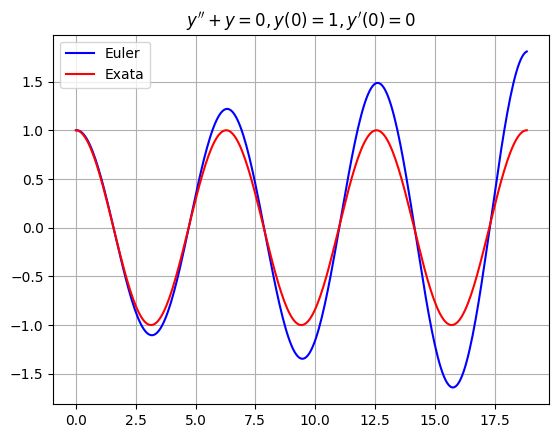

In [2]:
y0 = 1; v0 = 0;
t = np.linspace(0,3*2*np.pi,3*100)
y = np.zeros(len(t))
y[0] = y0
dy = np.zeros(len(t))
dy[0] = v0
for n in range(0,len(t)-1):
    h = t[n+1] - t[n]
    y[n+1] = y[n] + dy[n]*h
    dy[n+1] = dy[n] - y[n]*h
plt.plot(t,y,'b',t,np.cos(t),'r'), plt.grid(True)
plt.title(r"$y'' + y = 0 , y(0) = 1 , y'(0) = 0$")
plt.legend(["Euler","Exata"])
plt.show()

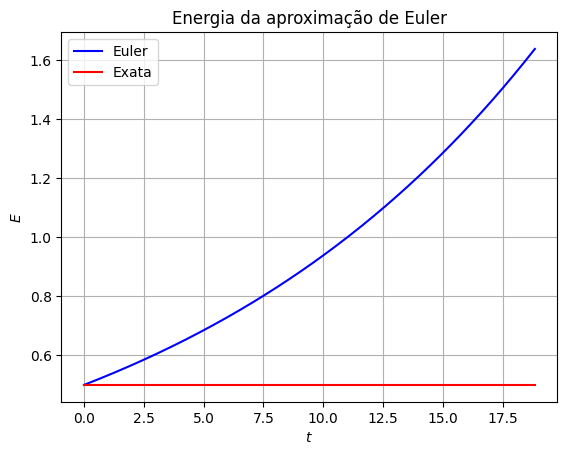

In [3]:
E = (y**2 + dy**2)/2
plt.plot(t,E,'b',t,0.5 + 0*t,'r'), plt.grid(True)
plt.title("Energia da aproximação de Euler"), plt.xlabel("$t$"), plt.ylabel("$E$")
plt.legend(["Euler","Exata"])
plt.show()

In [4]:
def odeEuler(f,t,y0):
    """Método de Euler para y' = f(t,y), y(t[0]) = y0.
    Funciona para equações escalares (y0 número) e para sistemas (y0 lista/array)."""
    y0 = np.asarray(y0, dtype=float)
    y = np.zeros((len(t),) + y0.shape)
    y[0] = y0
    for n in range(0,len(t)-1):
        h = t[n+1] - t[n]
        k1 = np.asarray(f(t[n],y[n]))
        y[n+1] = y[n] + k1*h
    return y

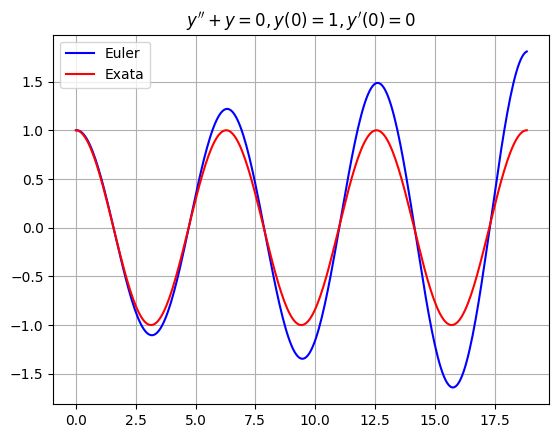

In [5]:
def f(t,u):
    dudt = np.zeros(2)
    dudt[0] = u[1]
    dudt[1] = -u[0]
    return dudt

t = np.linspace(0,3*2*np.pi,3*100)
u0 = [1,0]
U = odeEuler(f,t,u0)
plt.plot(t,U[:,0],'b',t,np.cos(t),'r'), plt.grid(True)
plt.title(r"$y'' + y = 0 , y(0) = 1 , y'(0) = 0$")
plt.legend(["Euler","Exata"])
plt.show()

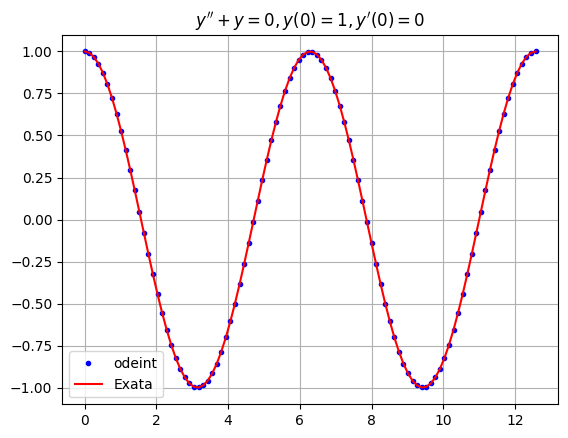

In [6]:
def f(u,t):
    dudt = np.zeros(2)
    dudt[0] = u[1]
    dudt[1] = -u[0]
    return dudt

t = np.linspace(0,2*2*np.pi,2*50)
u0 = [1,0]
U = spi.odeint(f,u0,t)
plt.plot(t,U[:,0],'b.',t,np.cos(t),'r'), plt.grid(True)
plt.title(r"$y'' + y = 0 , y(0) = 1 , y'(0) = 0$")
plt.legend(["odeint","Exata"])
plt.show()

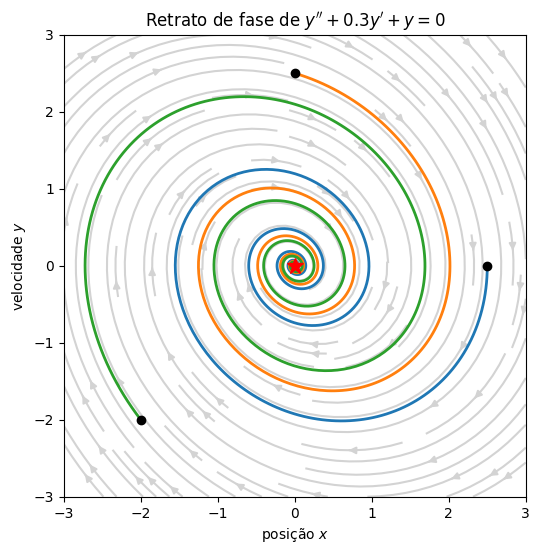

In [7]:
def f(u,t):
    return [u[1], -u[0] - 0.3*u[1]]

# campo vetorial em uma malha
x = np.linspace(-3,3,25); y = np.linspace(-3,3,25)
X, Y = np.meshgrid(x,y)
U = Y                     # x' = y
V = -X - 0.3*Y            # y' = -x - 0.3y
plt.figure(figsize=(6,6))
plt.streamplot(X,Y,U,V,color='lightgray',density=1.2)

# algumas trajetórias
t = np.linspace(0,30,1000)
for u0 in [[2.5,0],[0,2.5],[-2,-2]]:
    sol = spi.odeint(f,u0,t)
    plt.plot(sol[:,0],sol[:,1],lw=2)
    plt.plot(u0[0],u0[1],'ko')

plt.plot(0,0,'r*',markersize=12)      # equilíbrio
plt.xlabel("posição $x$"), plt.ylabel("velocidade $y$")
plt.title(r"Retrato de fase de $y'' + 0.3y' + y = 0$")
plt.axis('square'), plt.xlim([-3,3]), plt.ylim([-3,3])
plt.show()